In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import poisson



all_matches = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"], dtype={"season":str})
all_matches.shape
all_matches.head(5)


,date,Home_team,Away_team,Home_goals,Away_goals,Result,Home_odd,Draw_odd,Away_odd,season
0,2018-08-10,Man United,Leicester,2,1,H,1.57,3.9,7.50,1819
1,2018-08-11,Bournemouth,Cardiff,2,0,H,1.90,3.6,4.50,1819
2,2018-08-11,Fulham,Crystal Palace,0,2,A,2.50,3.4,3.00,1819
3,2018-08-11,Huddersfield,Chelsea,0,3,A,6.50,4.0,1.61,1819
4,2018-08-11,Newcastle,Tottenham,1,2,A,3.90,3.5,2.04,1819


Text(0.5, 1.0, 'Percent of possibilities')

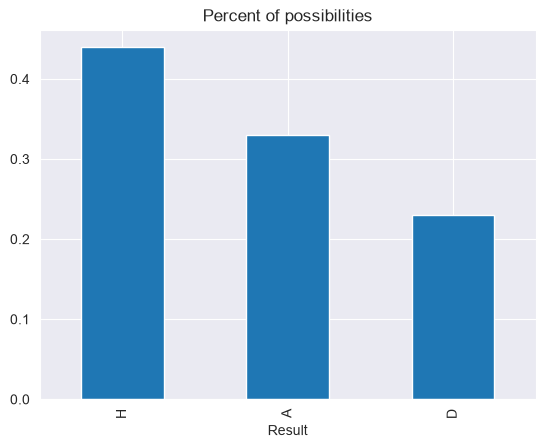

In [3]:
all_matches.value_counts("Result", normalize=True).plot(kind = "bar")
plt.title("Percent of possibilities")

In season 20/21 we can see that the away teams win more matches than home team, it might be connected to pancdemic conditions when stadiums were empty


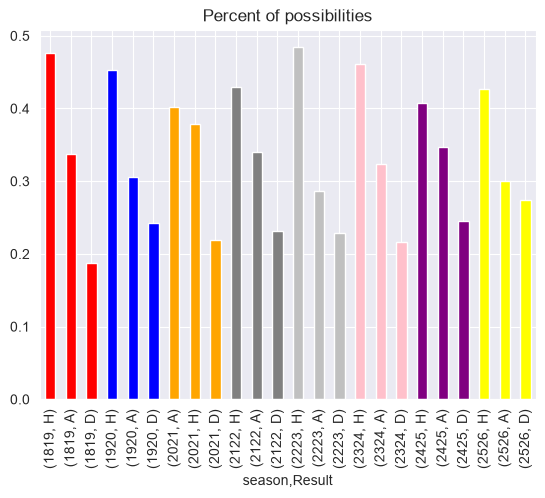

In [4]:
import matplotlib.pyplot as plt

# 1. Pobieramy dane
data = all_matches.groupby("season")["Result"].value_counts(normalize=True)


colors_dict = {
    "1819" : "red",
    "1920" : "blue",
    "2021" : "orange",
    "2122" : "grey",
    "2223" : "silver",
    "2324" : "pink",
    "2425" : "purple",
    "2526" : "yellow"
}

colors_list = data.index.get_level_values("season").astype(str).map(colors_dict)

# 3. Rysowanie wykresu
data.plot(kind="bar", color=colors_list)
plt.title("Percent of possibilities")
plt.show()



In [5]:
all_matches.groupby("season")["Result"].value_counts( normalize=True).unstack()[["H", "D", "A"]]


Result,H,D,A
season,,,
1819,0.476316,0.186842,0.336842
1920,0.452632,0.242105,0.305263
2021,0.378947,0.218421,0.402632
2122,0.428947,0.231579,0.339474
2223,0.484211,0.228947,0.286842
2324,0.460526,0.215789,0.323684
2425,0.407895,0.244737,0.347368
2526,0.426316,0.273684,0.300000


In [6]:
all_matches.groupby("season")["Home_goals"].mean()


season
1819    1.568421
1920    1.515789
2021    1.352632
2122    1.513158
2223    1.634211
2324    1.800000
2425    1.513158
2526    1.526316
Name: Home_goals, dtype: float64

Away teams scored on average less goals than home teams


In [7]:
home_mean = all_matches["Home_goals"].mean()
away_mean = all_matches["Away_goals"].mean()

home_mean


np.float64(1.5529605263157895)

In [8]:
away_mean

np.float64(1.305921052631579)

In [9]:
mean_goals = all_matches.groupby("season")[["Home_goals", "Away_goals"]].mean()
mean_goals

,Home_goals,Away_goals
season,,
1819,1.568421,1.252632
1920,1.515789,1.205263
2021,1.352632,1.342105
2122,1.513158,1.305263
2223,1.634211,1.218421
2324,1.800000,1.478947
2425,1.513158,1.421053
2526,1.526316,1.223684


In [10]:
mean_goals["difference"] = mean_goals["Home_goals"] - mean_goals["Away_goals"]
mean_goals

,Home_goals,Away_goals,difference
season,,,
1819,1.568421,1.252632,0.315789
1920,1.515789,1.205263,0.310526
2021,1.352632,1.342105,0.010526
2122,1.513158,1.305263,0.207895
2223,1.634211,1.218421,0.415789
2324,1.800000,1.478947,0.321053
2425,1.513158,1.421053,0.092105
2526,1.526316,1.223684,0.302632


On average Home teams score 0.2470 goals more than Away teams

In [11]:
mean_goals["difference"].min()

np.float64(0.010526315789473717)

In [12]:
mean_goals["difference"].mean()

np.float64(0.2470394736842106)

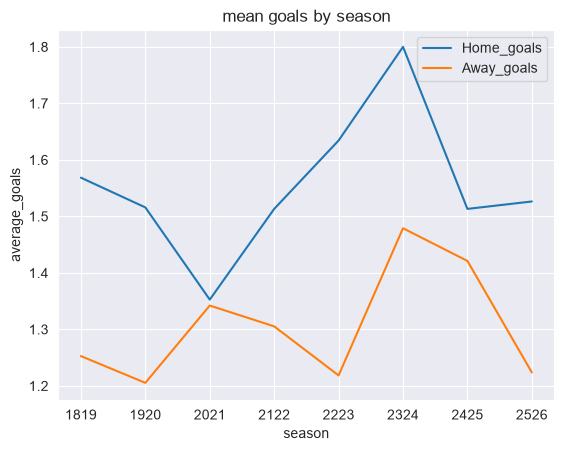

In [13]:
mean_goals[["Home_goals", "Away_goals"]].plot(kind="line")
plt.title("mean goals by season")
plt.xlabel("season")
plt.ylabel("average_goals")
plt.show()

In [14]:
empirical_home = all_matches.value_counts("Home_goals", normalize=True).sort_index()
empirical_home

Home_goals
0    0.231250
1    0.314145
2    0.243421
3    0.130921
4    0.053618
5    0.019408
6    0.004605
7    0.001645
8    0.000329
9    0.000658
Name: proportion, dtype: float64

In [15]:
empirical_away = all_matches.value_counts("Away_goals", normalize=True).sort_index()
empirical_away

Away_goals
0    0.290461
1    0.337500
2    0.222697
3    0.098026
4    0.033882
5    0.013158
6    0.003289
7    0.000329
8    0.000329
9    0.000329
Name: proportion, dtype: float64

In [16]:
max_goals = max(all_matches["Home_goals"].max(), all_matches["Away_goals"].max())

In [17]:
lam_home = home_mean # lambda home

k = range(0, max_goals + 1)

theoretical_home = poisson.pmf(k, lam_home)
print(f"lambda = (home team goals average):  {lam_home:.3f}")
theoretical_home


lambda = (home team goals average):  1.553


array([2.11620537e-01, 3.28638341e-01, 2.55181186e-01, 1.32095436e-01,
       5.12847495e-02, 1.59286383e-02, 4.12275776e-03, 9.14640008e-04,
       1.77549978e-04, 3.06364564e-05])

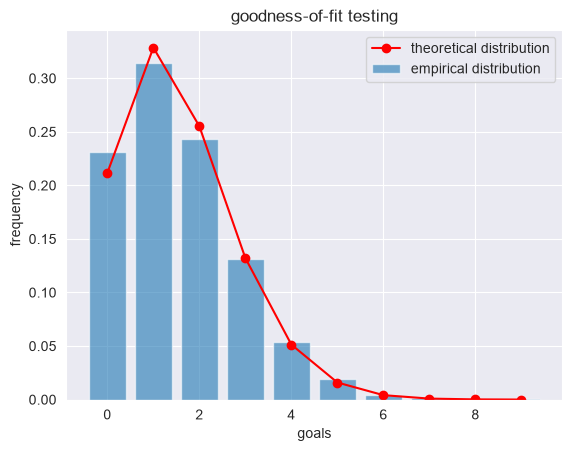

In [18]:
plt.bar(empirical_home.index, empirical_home.values, alpha = 0.6, label = 'empirical distribution')
plt.plot(k, theoretical_home, marker = "o", color = "red", label = "theoretical distribution" )
plt.title("goodness-of-fit testing")
plt.xlabel("goals")
plt.ylabel("frequency")
plt.legend()
plt.show()

Poisson model underestimate 0 goals and overestimate 1 and 2 goals


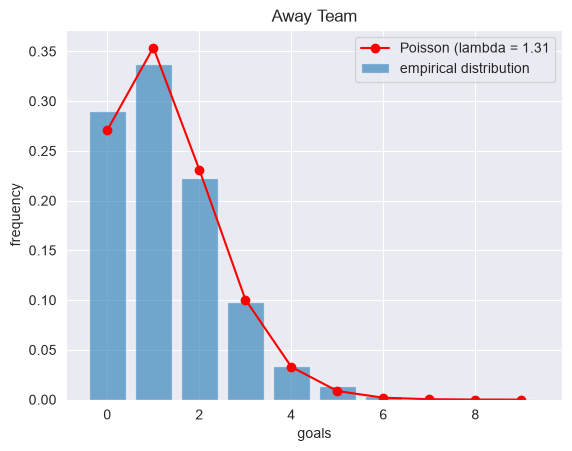

In [19]:
def plot_poisson_fit(goals, title, max_goals):
    empirical = goals.value_counts(normalize=True).sort_index()
    lam = goals.mean()
    k = range(0, max_goals + 1)
    theoretical = poisson.pmf(k, lam)

    plt.bar(empirical.index, empirical.values, alpha = 0.6, label = 'empirical distribution')
    plt.plot(k, theoretical, marker = "o", color = "red", label = f"Poisson (lambda = {lam:.2f}")
    plt.title(title)
    plt.xlabel("goals")
    plt.ylabel("frequency")
    plt.legend()
    plt.show()

plot_poisson_fit(all_matches["Away_goals"], "Away Team", max_goals)




Poisson model underestimate 0 goals and overestimate 1 and 2 goals


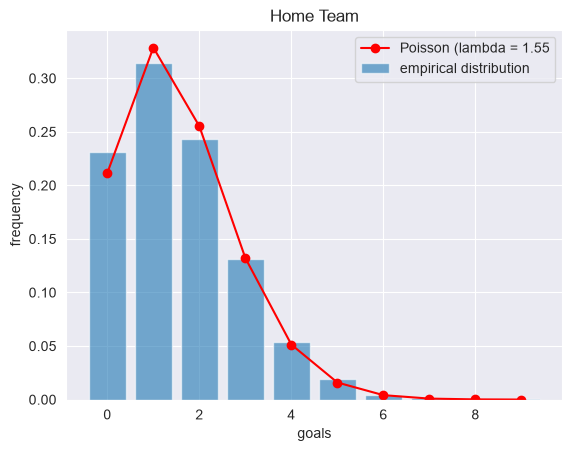

In [20]:
plot_poisson_fit(all_matches["Home_goals"], "Home Team", max_goals)

In [21]:
for team in ["Home_goals", "Away_goals"]:
    mean = all_matches[team].mean()
    var = all_matches[team].var()
    print(f"{team}: mean : {mean:.3f}, variance : {var:.3f}, variance/mean : {var/mean:.2f}")

Home_goals: mean : 1.553, variance : 1.719, variance/mean : 1.11
Away_goals: mean : 1.306, variance : 1.459, variance/mean : 1.12


varance is little greater than mean in both cases,  daviation is small so we can use poisson model,
In fact goals are more dotted. Poisson model can underestimate extreme results like 0 goals or 7 and more golas. It might result from unequal matches between leader and bottom of the table team and equal matches between middle table teams

In [30]:
k = ["Home_odd", "Draw_odd", "Away_odd"]

all_matches["prob_home"] = 1 / all_matches["Home_odd"]
all_matches["prob_draw"] = 1 / all_matches["Draw_odd"]
all_matches["prob_away"] = 1 / all_matches["Away_odd"]

all_matches


,date,Home_team,Away_team,Home_goals,Away_goals,Result,Home_odd,Draw_odd,Away_odd,season,prob_home,prob_draw,prob_away
0,2018-08-10,Man United,Leicester,2,1,H,1.57,3.9,7.50,1819,0.636943,0.256410,0.133333
1,2018-08-11,Bournemouth,Cardiff,2,0,H,1.90,3.6,4.50,1819,0.526316,0.277778,0.222222
2,2018-08-11,Fulham,Crystal Palace,0,2,A,2.50,3.4,3.00,1819,0.400000,0.294118,0.333333
3,2018-08-11,Huddersfield,Chelsea,0,3,A,6.50,4.0,1.61,1819,0.153846,0.250000,0.621118
4,2018-08-11,Newcastle,Tottenham,1,2,A,3.90,3.5,2.04,1819,0.256410,0.285714,0.490196
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3035,2026-05-24,Crystal Palace,Arsenal,1,2,A,4.20,4.0,1.75,2526,0.238095,0.250000,0.571429
3036,2026-05-24,Burnley,Wolves,1,1,D,2.35,3.5,2.90,2526,0.425532,0.285714,0.344828
3037,2026-05-24,Brighton,Man United,0,3,A,1.85,4.2,3.60,2526,0.540541,0.238095,0.277778
3038,2026-05-24,Fulham,Newcastle,2,0,H,2.88,3.8,2.25,2526,0.347222,0.263158,0.444444


In [34]:
all_matches["overround"] = all_matches[["prob_home", "prob_draw", "prob_away"]].sum(axis=1)
all_matches.describe()
#all_matches.head(15)

,date,Home_goals,Away_goals,Home_odd,Draw_odd,Away_odd,prob_home,prob_draw,prob_away,overround
count,3040,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000
mean,2022-07-10 22:30:28.421052,1.552961,1.305921,2.932303,4.281309,4.550240,0.461257,0.249625,0.340069,1.050951
min,2018-08-10 00:00:00,0.000000,0.000000,1.060000,2.800000,1.120000,0.043478,0.058824,0.024390,1.019298
25%,2020-08-31 00:00:00,1.000000,0.000000,1.620000,3.500000,2.200000,0.303030,0.222222,0.190476,1.048855
50%,2022-06-28 12:00:00,1.000000,1.000000,2.250000,3.800000,3.200000,0.444444,0.263158,0.312500,1.053030
75%,2024-06-10 06:00:00,2.000000,2.000000,3.300000,4.500000,5.250000,0.617284,0.285714,0.454545,1.056818
max,2026-05-24 00:00:00,9.000000,9.000000,23.000000,17.000000,41.000000,0.943396,0.357143,0.892857,1.166667
std,NaN,1.311035,1.207835,2.241399,1.416611,4.051381,0.206820,0.052298,0.189656,0.010749


In [35]:
margin = (all_matches["overround"].mean() - 1)*100
print(f"average margin: {margin:.2f}%")

average margin: 5.10%


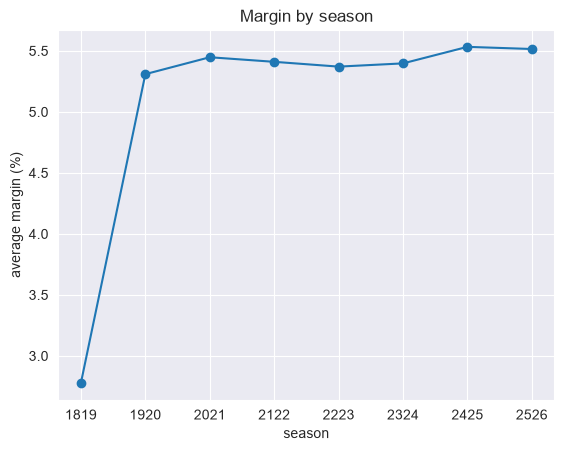

In [39]:
~~~~margin_by_season = (all_matches.groupby("season")["overround"].mean() - 1)*100
margin_by_season.plot(kind="line", marker = "o")
plt.title("Margin by season")
plt.xlabel("season")
plt.ylabel("average margin (%)")
plt.show()

In [51]:
all_matches["fair_home"] = all_matches["prob_home"]/all_matches["overround"]
all_matches["fair_draw"] = all_matches["prob_draw"]/all_matches["overround"]
all_matches["fair_away"] = all_matches["prob_away"]/all_matches["overround"]

market_home = all_matches["fair_home"].mean()
actual_home = (all_matches["Result"] == "H").mean()

print(f"Market predict home win in average of: {market_home:.1%} ")
print(f"In fact, home win in: {actual_home:.1%} ")

Market predict home win in average of: 43.9% 
In fact, home win in: 43.9% 


In [52]:
all_matches

,date,Home_team,Away_team,Home_goals,Away_goals,Result,Home_odd,Draw_odd,Away_odd,season,prob_home,prob_draw,prob_away,overround,fair_home,fair_draw,fair_away
0,2018-08-10,Man United,Leicester,2,1,H,1.57,3.9,7.50,1819,0.636943,0.256410,0.133333,1.026686,0.620387,0.249745,0.129868
1,2018-08-11,Bournemouth,Cardiff,2,0,H,1.90,3.6,4.50,1819,0.526316,0.277778,0.222222,1.026316,0.512821,0.270655,0.216524
2,2018-08-11,Fulham,Crystal Palace,0,2,A,2.50,3.4,3.00,1819,0.400000,0.294118,0.333333,1.027451,0.389313,0.286260,0.324427
3,2018-08-11,Huddersfield,Chelsea,0,3,A,6.50,4.0,1.61,1819,0.153846,0.250000,0.621118,1.024964,0.150099,0.243911,0.605990
4,2018-08-11,Newcastle,Tottenham,1,2,A,3.90,3.5,2.04,1819,0.256410,0.285714,0.490196,1.032321,0.248382,0.276769,0.474849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3035,2026-05-24,Crystal Palace,Arsenal,1,2,A,4.20,4.0,1.75,2526,0.238095,0.250000,0.571429,1.059524,0.224719,0.235955,0.539326
3036,2026-05-24,Burnley,Wolves,1,1,D,2.35,3.5,2.90,2526,0.425532,0.285714,0.344828,1.056074,0.402938,0.270544,0.326518
3037,2026-05-24,Brighton,Man United,0,3,A,1.85,4.2,3.60,2526,0.540541,0.238095,0.277778,1.056414,0.511675,0.225381,0.262944
3038,2026-05-24,Fulham,Newcastle,2,0,H,2.88,3.8,2.25,2526,0.347222,0.263158,0.444444,1.054825,0.329175,0.249480,0.421344
